In [1]:
# 04 - CNN (TP7): a CNN on the Mel spectrograms of the heart sounds, 3 folds (validation) + 1 test, MLflow
#
# 1. each clean wav -> a Mel spectrogram of 40 bands x 157 moments (5 s at 2000 Hz) = a grey image
# 2. the fixed TEST set of notebook 01: 20% of the wavs, put aside, never used to train or to choose a setting
# 3. VALIDATION: the 3 folds (KFold, the same as all the notebooks) on the 80% train part:
#    for each fold, the training vs validation curves, the confusion matrix and the ROC curve
# 4. TEST: the final CNN learns on the whole 80% part, then it is tested ONCE on the 20% test set
#    (confusion matrix, ROC curve, classification report). This tested CNN is the one saved and deployed.
# 5. MLflow (experiment audio_benchmark_final): params, validation + test metrics, plots, the CNN, 1 run per fold
#
# Before running: notebook 01 made splits/test_files.json, and the MLflow container runs (docker compose up -d mlflow-server)

In [2]:
# The first time only: install TensorFlow (Keras comes with it)
# Then click "Restart" (the kernel) and run the notebook from the top.
%pip install tensorflow==2.21.0

Note: you may need to restart the kernel to use updated packages.Requirement already satisfied: tensorflow==2.21.0 in d:\mlops_project\venv\lib\site-packages (2.21.0)



You should consider upgrading via the 'D:\MLOps_Project\venv\Scripts\python.exe -m pip install --upgrade pip' command.


In [3]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"    # hide the TensorFlow info messages

import json
import pickle
from glob import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import librosa
import IPython.display as ipd

from sklearn.model_selection import KFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.metrics import roc_curve, auc                 # the ROC curve and the area under it (AUC)

import keras
from keras.models import Sequential
from keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from keras.optimizers import Adam

import mlflow
import mlflow.keras

In [4]:
# my folders (the same as in the other notebooks)
project_folder = "D:/MLOps_Project/"
ourdataset_folder = "D:/MLOps_Project/ourdataset/train/"
plots_folder = "D:/MLOps_Project/models plots/"    # the figures of the notebooks (saved here, then sent to MLflow)


def load_data(file_name):
    with open(file_name, "rb") as f:
        return pickle.load(f)


def save_data(data, file_name):
    with open(file_name, "wb") as f:
        pickle.dump(data, f)

In [5]:
# ==================== Merge: Farah vs Zaineb (the result of notebook 09, part 2) ====================
# For the CNN we tried Farah's CNN, Zaineb's CNN (BatchNorm + GlobalAveragePooling + softmax + early stopping) and 2
# merged CNNs (Farah's blocks + BatchNorm + class_weight + early stopping on 10% of the training fold, with Flatten or
# GlobalAveragePooling), with the SAME protocol: the same 3681 clean wavs, the same 80% train part, the same 3
# validation folds, the same metrics (the 20% test set is never used to choose). Rule: a candidate replaces the
# current version if it has a higher validation recall (if it loses more than 0.01 of F1 it is a trade-off and we
# keep the higher recall, the PDF rule), or a higher F1 without losing more than 0.01 of recall.
# Accuracy alone is misleading here: Zaineb's CNN has the best accuracy (0.865) because it says "normal" more often,
# but it finds only 67% of the sick hearts, against 94% for Farah's CNN.
# -> the winner = Farah's CNN (the trade-offs are written in MERGE_NOTES.md)
with open(plots_folder + "merge_results.json") as f:
    merge = json.load(f)["CNN"]
ipd.display(pd.DataFrame(merge["candidates"])[["name", "from", "recall", "f1", "precision", "accuracy", "kept"]])
print("Kept:", merge["winner"])
assert merge["winner"] == "farah", "the winner changed: update this notebook"

,name,from,recall,f1,precision,accuracy,kept
0,"Farah: Conv + MaxPool, Flatten, Dense 32, 20 e...",Farah,0.938,0.628,0.472,0.750,True
1,"Zaineb: BatchNorm + GAP + softmax, early stopp...",Zaineb,0.668,0.690,0.715,0.865,False
2,"merged: + BatchNorm + early stopping, Flatten ...",merged,0.534,0.411,0.364,0.773,False
3,"merged: + BatchNorm + early stopping, GAP [22,...",merged,0.692,0.660,0.639,0.838,False


Kept: farah


In [6]:
# ==================== From a wav to a Mel spectrogram (the "image" of the sound) ====================
SR = 2000        # every wav at 2000 Hz (like in the project: heart sounds are below 1000 Hz)
SECONDS = 5      # every wav = 5 seconds, because the CNN needs images of the same size


def get_spectrogram(file):
    signal, rate = librosa.load(file, sr=SR)

    # skip the broken wavs (the same rules as notebook 01, TP3 and TP4)
    too_short = len(signal) < 2 * SR                       # less than 2 seconds
    silent = np.max(np.abs(signal)) < 0.001                # almost no sound
    saturated = np.mean(np.abs(signal) >= 0.99) > 0.01     # more than 1% of the samples at the maximum
    if too_short or silent or saturated:
        return None

    # the same size for every wav: we keep the middle 5 seconds (a shorter wav is repeated)
    n = SR * SECONDS                                       # 10000 samples
    if len(signal) < n:
        signal = np.tile(signal, n // len(signal) + 1)[:n]
    else:
        start = (len(signal) - n) // 2
        signal = signal[start:start + n]

    # the Mel spectrogram in dB (course 2): 40 mel bands x 157 moments
    S = librosa.feature.melspectrogram(y=signal, sr=rate, n_fft=256, hop_length=64, n_mels=40)
    S_DB = librosa.power_to_db(S, ref=np.max)
    return S_DB

In [7]:
# reads all the wavs (a few minutes): run it once, after that the 3 .data files are enough
spectrograms = []
labels = []
files = []          # the name of each wav: to find the wavs of the test set (splits/test_files.json)
for class_name in ["abnormal", "normal"]:
    for file in glob(ourdataset_folder + class_name + "/*.wav"):
        S_DB = get_spectrogram(file)
        if S_DB is None:          # broken wav -> we skip it
            continue
        spectrograms.append(S_DB)
        files.append(os.path.basename(file))
        if class_name == "abnormal":
            labels.append(1)
        else:
            labels.append(0)

save_data(spectrograms, project_folder + "cnn_spectrograms.data")
save_data(labels, project_folder + "cnn_labels.data")
save_data(files, project_folder + "cnn_files.data")
print(len(spectrograms), "spectrograms of size", spectrograms[0].shape)

3681 spectrograms of size (40, 157)


X: (3681, 40, 157, 1) | normal: 2855 | abnormal: 826


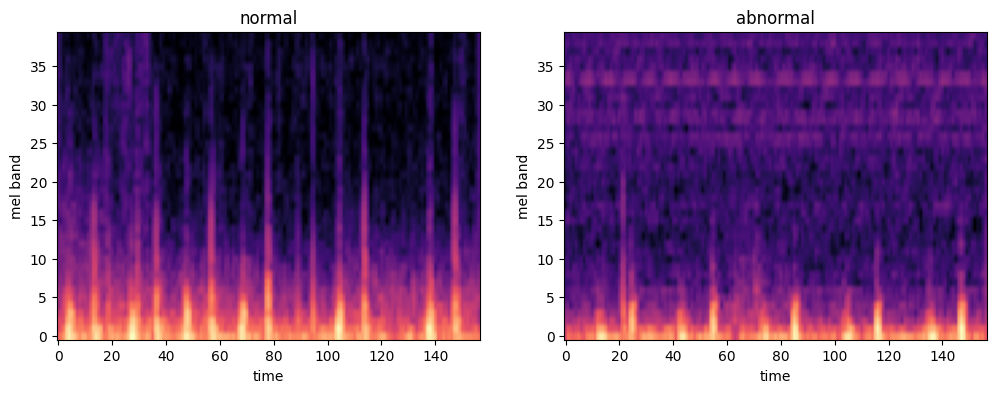

In [8]:
spectrograms = load_data(project_folder + "cnn_spectrograms.data")
labels = load_data(project_folder + "cnn_labels.data")
files = np.array(load_data(project_folder + "cnn_files.data"))

X = np.array(spectrograms)     # (number of wavs, 40, 157)
y = np.array(labels)           # 1 = abnormal, 0 = normal

X = (X + 80) / 80              # dB from -80 to 0 -> numbers from 0 to 1 (like dividing the pixels by 255 in the course)
X = X.reshape(X.shape[0], 40, 157, 1)    # add 1 channel at the end, like a grey image

print("X:", X.shape, "| normal:", np.sum(y == 0), "| abnormal:", np.sum(y == 1))

# what the CNN sees: 1 normal and 1 abnormal spectrogram
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.imshow(X[y == 0][0, :, :, 0], aspect="auto", origin="lower", cmap="magma")
plt.title("normal")
plt.xlabel("time")
plt.ylabel("mel band")
plt.subplot(1, 2, 2)
plt.imshow(X[y == 1][0, :, :, 0], aspect="auto", origin="lower", cmap="magma")
plt.title("abnormal")
plt.xlabel("time")
plt.ylabel("mel band")
plt.show()

In [9]:
# ==================== The fixed TEST set (made by notebook 01): put aside, never used to train ====================
# - 80% = the TRAIN part: the 3 folds (validation) and the training of the final CNN happen only here
# - 20% = the TEST part: used ONCE at the end, to test the final CNN (never to choose the epochs or a setting)
with open(project_folder + "splits/test_files.json") as f:
    split = json.load(f)
test_label = dict(zip(split["test_files"], split["test_labels"]))    # name of a test wav -> its class

assert len(files) == len(X) == len(y), "the .data files do not match: run the cell that reads the wavs again"
is_test = np.array([name in test_label for name in files])          # True for the 20% test wavs
assert is_test.sum() == split["n_test"], "some test wavs are missing: run notebook 01 again"
for i in np.where(is_test)[0]:
    assert y[i] == test_label[files[i]], "the class of " + files[i] + " is not the same in notebook 01"

X_train, y_train = X[~is_test], y[~is_test]    # ~ = "not": the 80% train part
X_test, y_test = X[is_test], y[is_test]
print("train (80%):", len(y_train), "wavs (abnormal:", np.sum(y_train == 1), ") | test (20%):", len(y_test),
      "wavs (abnormal:", np.sum(y_test == 1), ")")

train (80%): 2944 wavs (abnormal: 661 ) | test (20%): 737 wavs (abnormal: 165 )


In [10]:
# ==================== Our CNN ====================
def build_cnn():
    model = Sequential()
    model.add(Input(shape=(40, 157, 1)))         # 1 spectrogram = a grey image of 40 x 157

    # block 1: 16 filters of 3x3 look for small patterns (like the vertical line detector of the course)
    model.add(Conv2D(16, (3, 3), activation="relu"))
    model.add(MaxPooling2D((2, 2)))              # keeps the max of each 2x2 square: the image becomes 2x smaller

    # block 2: 32 filters, they combine the patterns found by block 1
    model.add(Conv2D(32, (3, 3), activation="relu"))
    model.add(MaxPooling2D((2, 2)))

    # block 3: 64 filters
    model.add(Conv2D(64, (3, 3), activation="relu"))
    model.add(MaxPooling2D((2, 2)))

    model.add(Flatten())                         # the feature maps become 1 long vector
    model.add(Dense(32, activation="relu"))      # a fully connected layer (a classic neural network)
    model.add(Dropout(0.5))                      # switches off 50% of the neurons while training -> less overfitting
    model.add(Dense(1, activation="sigmoid"))    # 1 neuron: the probability that the heart is abnormal

    # Adam = the optimizer (it changes the weights), binary cross-entropy = the loss for 2 classes
    model.compile(optimizer=Adam(learning_rate=0.001), loss="binary_crossentropy", metrics=["accuracy"])
    return model


build_cnn().summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 38, 155, 16)    │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 19, 77, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 17, 75, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 37, 32)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 6, 35, 64)      │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 3, 17, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3264)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │       104,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 127,809 (499.25 KB)

 Trainable params: 127,809 (499.25 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
# ==================== The plots of the notebook ====================
def PlotConfusionMatrix(cm, title):
    # cm[i][j] = number of wavs of class i (true) that the CNN put in class j (predicted)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=["normal", "abnormal"], yticklabels=["normal", "abnormal"])
    plt.title(title)
    plt.xlabel("Predicted class")
    plt.ylabel("True class")


def plot_roc(y_true, y_score, title):
    # ROC curve: for every threshold (not only 0.5), the % of sick hearts found (true positive rate = recall)
    # against the % of normal hearts called abnormal (false positive rate). AUC = area under it (1 = perfect, 0.5 = random)
    false_positive_rate, true_positive_rate, thresholds = roc_curve(y_true, y_score)
    area = auc(false_positive_rate, true_positive_rate)
    plt.plot(false_positive_rate, true_positive_rate, label="AUC = {:.3f}".format(area))
    plt.plot([0, 1], [0, 1], "--", color="grey", label="random")
    plt.title(title)
    plt.xlabel("False positive rate")
    plt.ylabel("True positive rate (recall)")
    plt.legend(loc="lower right")
    return area


# like plot_acc_loss(): accuracy and loss after each epoch, train vs validation + the confusion matrix and the
# ROC curve of the validation wavs of this fold -> 1 figure per fold
def plot_fold(history, y_true, y_prob, fold):
    plt.figure(figsize=(22, 4.5))
    plt.subplot(1, 4, 1)
    plt.plot(history.history["accuracy"], label="train")
    plt.plot(history.history["val_accuracy"], label="validation")
    plt.title("Fold " + str(fold) + " - accuracy")
    plt.xlabel("epoch")
    plt.legend()
    plt.subplot(1, 4, 2)
    plt.plot(history.history["loss"], label="train")
    plt.plot(history.history["val_loss"], label="validation")
    plt.title("Fold " + str(fold) + " - loss")
    plt.xlabel("epoch")
    plt.legend()
    plt.subplot(1, 4, 3)
    PlotConfusionMatrix(confusion_matrix(y_true, (y_prob > 0.5).astype(int)), "Fold " + str(fold) + " - validation")
    plt.subplot(1, 4, 4)
    plot_roc(y_true, y_prob, "Fold " + str(fold) + " - ROC (validation)")
    plt.tight_layout()
    plt.savefig(plots_folder + "tp7_cnn_val_fold" + str(fold) + ".png")
    plt.show()

class_weight: {0: np.float64(0.6447656592203241), 1: np.float64(2.226928895612708)}
==================== Fold 1


              precision    recall  f1-score   support

      normal       0.97      0.72      0.83       756
    abnormal       0.50      0.93      0.65       226

    accuracy                           0.77       982
   macro avg       0.73      0.83      0.74       982
weighted avg       0.86      0.77      0.78       982



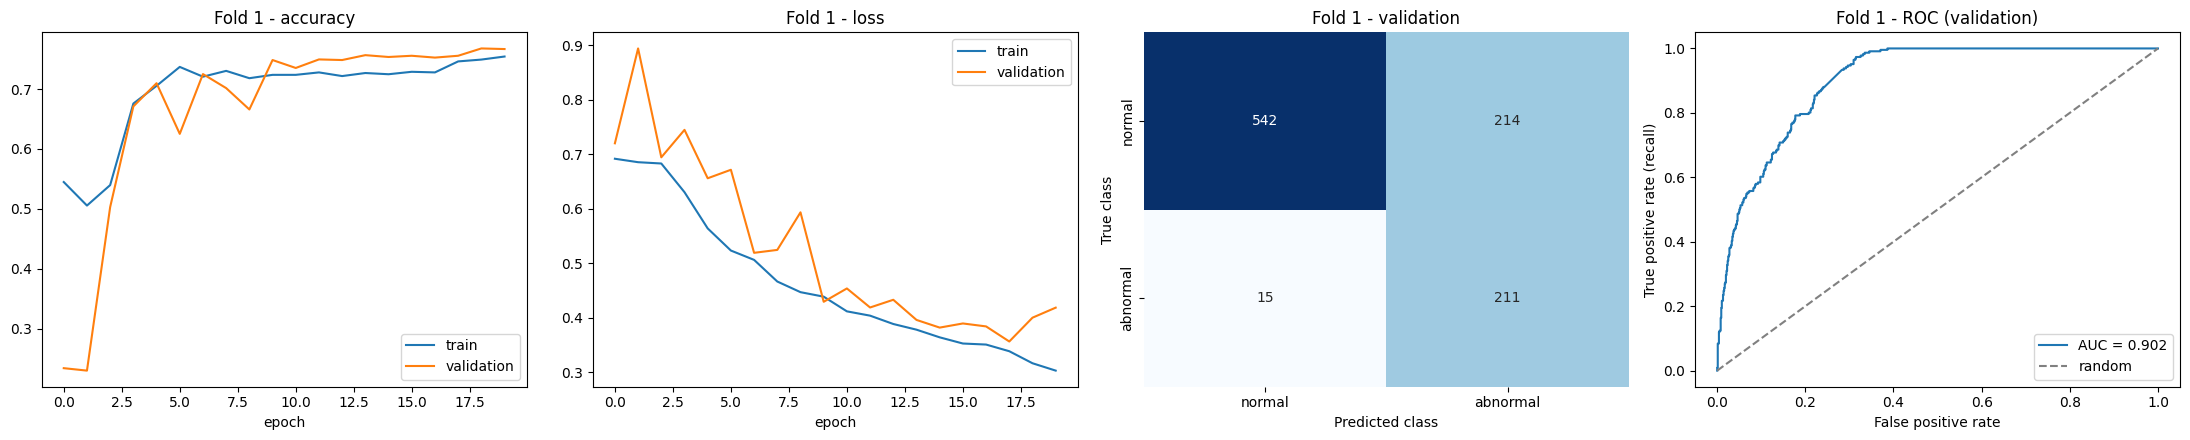

==================== Fold 2


              precision    recall  f1-score   support

      normal       0.97      0.69      0.80       759
    abnormal       0.46      0.92      0.62       222

    accuracy                           0.74       981
   macro avg       0.71      0.80      0.71       981
weighted avg       0.85      0.74      0.76       981



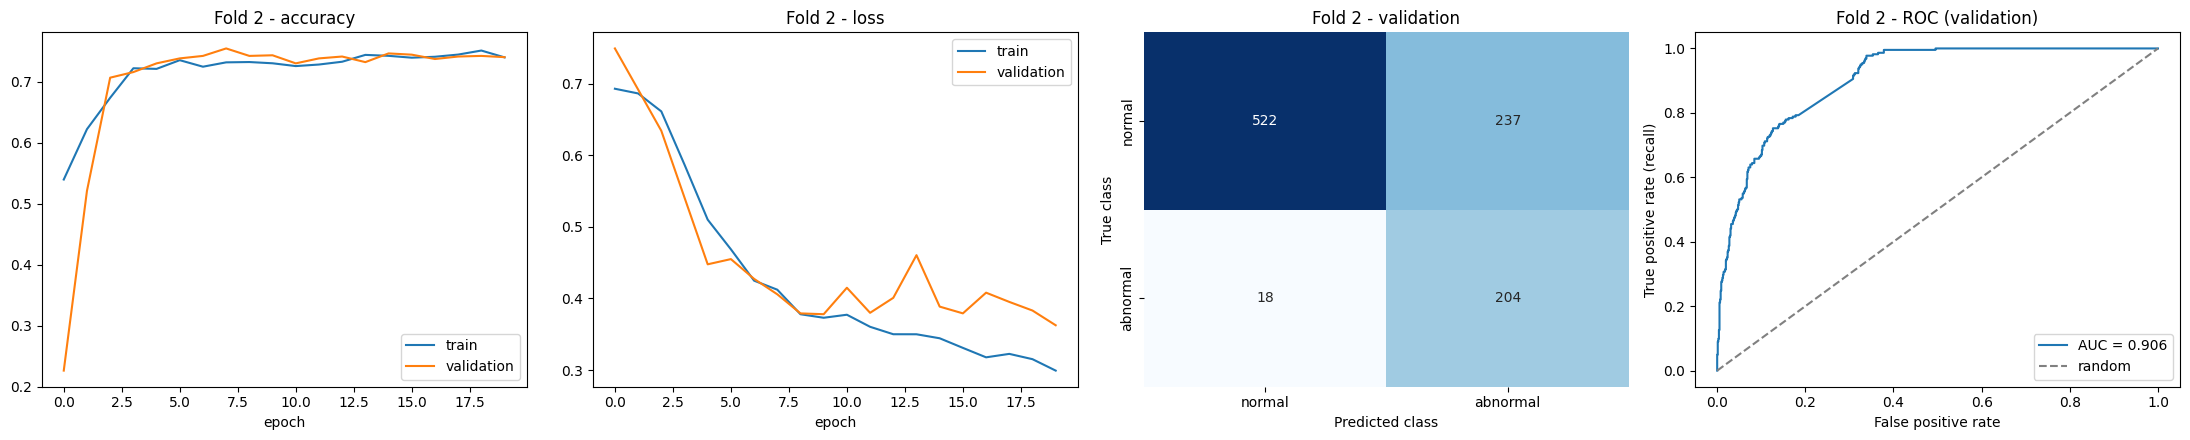

==================== Fold 3


              precision    recall  f1-score   support

      normal       0.98      0.68      0.81       768
    abnormal       0.46      0.96      0.62       213

    accuracy                           0.74       981
   macro avg       0.72      0.82      0.71       981
weighted avg       0.87      0.74      0.77       981



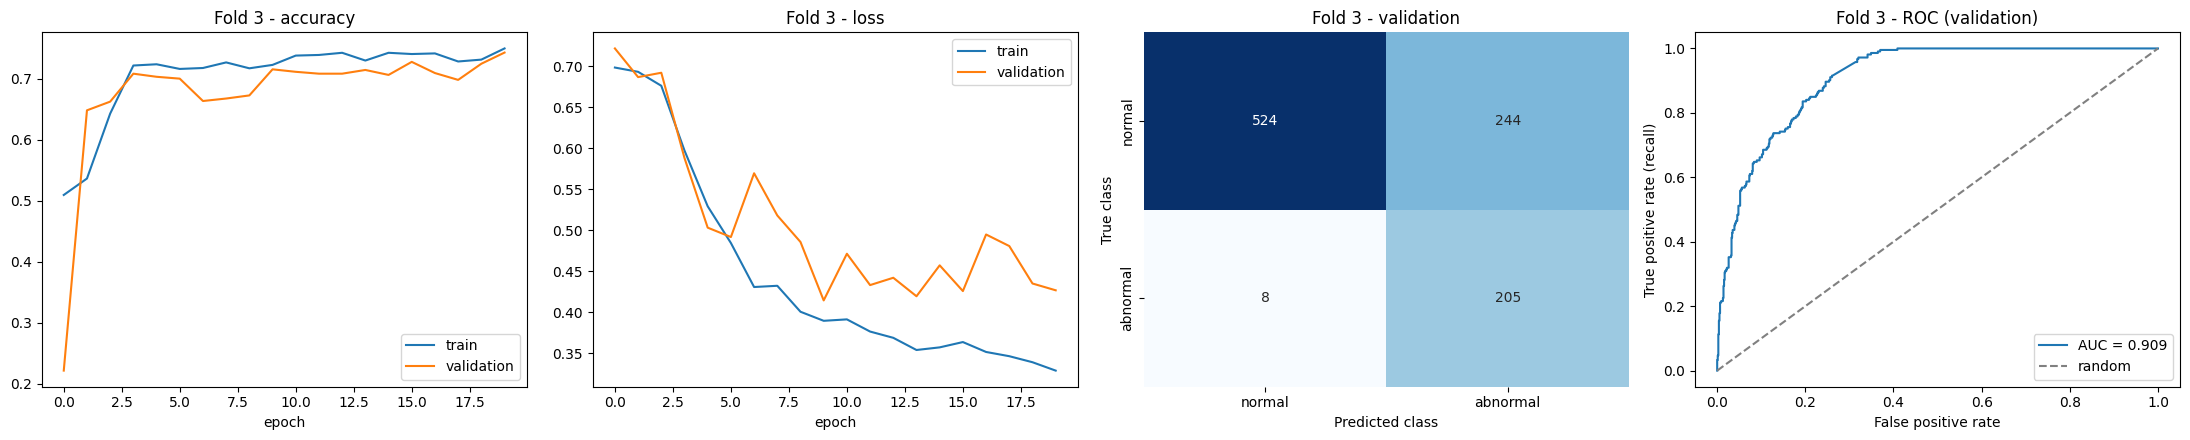

In [12]:
# ==================== VALIDATION: 3 folds on the 80% train part (like TP3) ====================
EPOCHS = 20         # 20 passes over the train wavs
BATCH_SIZE = 32     # the weights change after every 32 wavs

# we have 3.5x less abnormal wavs, so each abnormal wav counts 3.5x more (like class_weight="balanced" in TP3)
# (computed on the train part only: the test wavs stay unknown)
class_weight = {0: len(y_train) / (2 * np.sum(y_train == 0)), 1: len(y_train) / (2 * np.sum(y_train == 1))}
print("class_weight:", class_weight)

kfold = KFold(n_splits=3, shuffle=True, random_state=1)    # the same 3 folds as TP3, TP4 and TP8
results = []
histories = []      # the Keras history of each fold (its curves), kept for MLflow
oof_prob = np.zeros(len(y_train))               # the "out-of-fold" probability of each train wav (for notebook 08)
oof_fold = np.zeros(len(y_train), dtype=int)    # the fold where the wav was in validation
fold = 1
for train_index, val_index in kfold.split(X_train):
    print("==================== Fold", fold)
    X_tr, X_val = X_train[train_index], X_train[val_index]       # 2/3 of the train part to learn, 1/3 to validate
    y_tr, y_val = y_train[train_index], y_train[val_index]

    keras.utils.set_random_seed(0)      # the same random start each time -> the same results if we run it again
    model = build_cnn()
    history = model.fit(X_tr, y_tr, epochs=EPOCHS, batch_size=BATCH_SIZE, class_weight=class_weight,
                        validation_data=(X_val, y_val), verbose=0)
    # validation_data: the CNN does NOT learn from the validation wavs, they are only used to draw the curves
    # verbose=0: nothing is printed while it trains (a minute or two per fold), the curves show every epoch

    # the sigmoid gives a probability: more than 0.5 -> abnormal (1), else normal (0)
    y_prob = model.predict(X_val, verbose=0).ravel()
    y_pred = (y_prob > 0.5).astype(int)
    oof_prob[val_index] = y_prob
    oof_fold[val_index] = fold
    false_positive_rate, true_positive_rate, thresholds = roc_curve(y_val, y_prob)

    print(classification_report(y_val, y_pred, target_names=["normal", "abnormal"]))
    results.append({
        "fold": fold,
        "accuracy": accuracy_score(y_val, y_pred),
        "precision": precision_score(y_val, y_pred),    # precision, recall, f1: of the abnormal class
        "recall": recall_score(y_val, y_pred),
        "f1": f1_score(y_val, y_pred),
        "auc": auc(false_positive_rate, true_positive_rate),    # the area under the ROC curve
        "y_val": y_val,                                  # kept for the summary figure
        "y_prob": y_prob,
    })
    plot_fold(history, y_val, y_prob, fold)
    histories.append(history)
    fold = fold + 1

   fold  accuracy  precision  recall     f1    auc
0     1     0.767      0.496   0.934  0.648  0.902
1     2     0.740      0.463   0.919  0.615  0.906
2     3     0.743      0.457   0.962  0.619  0.909

Mean of the 3 folds (validation):
accuracy     0.750
precision    0.472
recall       0.938
f1           0.628
auc          0.905
dtype: float64


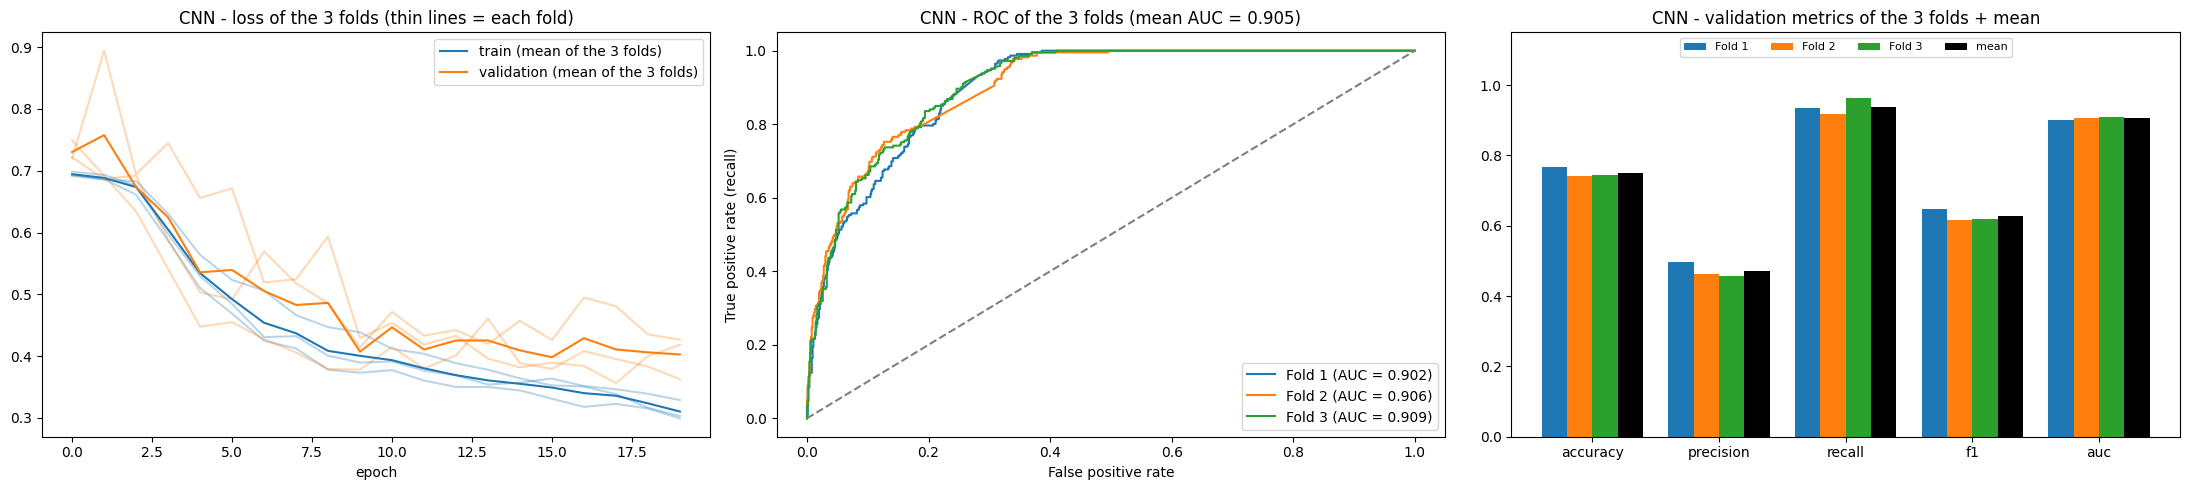

In [13]:
table = pd.DataFrame(results)[["fold", "accuracy", "precision", "recall", "f1", "auc"]]
print(table.round(3))
print()
print("Mean of the 3 folds (validation):")
print(table[["accuracy", "precision", "recall", "f1", "auc"]].mean().round(3))

# ONE summary figure of the validation: the loss curves of the 3 folds, their ROC curves, their metrics + the mean
metrics = ["accuracy", "precision", "recall", "f1", "auc"]
plt.figure(figsize=(22, 5))

plt.subplot(1, 3, 1)
for i in range(3):    # thin lines: each fold
    plt.plot(histories[i].history["loss"], color="tab:blue", alpha=0.3)
    plt.plot(histories[i].history["val_loss"], color="tab:orange", alpha=0.3)
plt.plot(np.mean([h.history["loss"] for h in histories], axis=0), color="tab:blue", label="train (mean of the 3 folds)")
plt.plot(np.mean([h.history["val_loss"] for h in histories], axis=0), color="tab:orange",
         label="validation (mean of the 3 folds)")
plt.title("CNN - loss of the 3 folds (thin lines = each fold)")
plt.xlabel("epoch")
plt.legend()

plt.subplot(1, 3, 2)
for r in results:
    false_positive_rate, true_positive_rate, thresholds = roc_curve(r["y_val"], r["y_prob"])
    plt.plot(false_positive_rate, true_positive_rate, label="Fold " + str(r["fold"]) + " (AUC = {:.3f})".format(r["auc"]))
plt.plot([0, 1], [0, 1], "--", color="grey")
plt.title("CNN - ROC of the 3 folds (mean AUC = {:.3f})".format(table["auc"].mean()))
plt.xlabel("False positive rate")
plt.ylabel("True positive rate (recall)")
plt.legend(loc="lower right")

plt.subplot(1, 3, 3)
x = np.arange(len(metrics))
for i in range(3):
    plt.bar(x - 0.3 + 0.2 * i, table.loc[i, metrics], width=0.2, label="Fold " + str(i + 1))
plt.bar(x + 0.3, table[metrics].mean(), width=0.2, color="black", label="mean")
plt.xticks(x, metrics)
plt.ylim(0, 1.15)
plt.title("CNN - validation metrics of the 3 folds + mean")
plt.legend(loc="upper center", ncol=4, fontsize=8)

plt.tight_layout()
plt.savefig(plots_folder + "tp7_cnn_val_summary.png")
plt.show()

final CNN trained on 2944 wavs (the 80% train part)


              precision    recall  f1-score   support

      normal       0.97      0.76      0.85       572
    abnormal       0.52      0.91      0.66       165

    accuracy                           0.79       737
   macro avg       0.74      0.83      0.75       737
weighted avg       0.87      0.79      0.81       737

{'accuracy': 0.791, 'precision': 0.519, 'recall': 0.909, 'f1': 0.661, 'auc': 0.932}


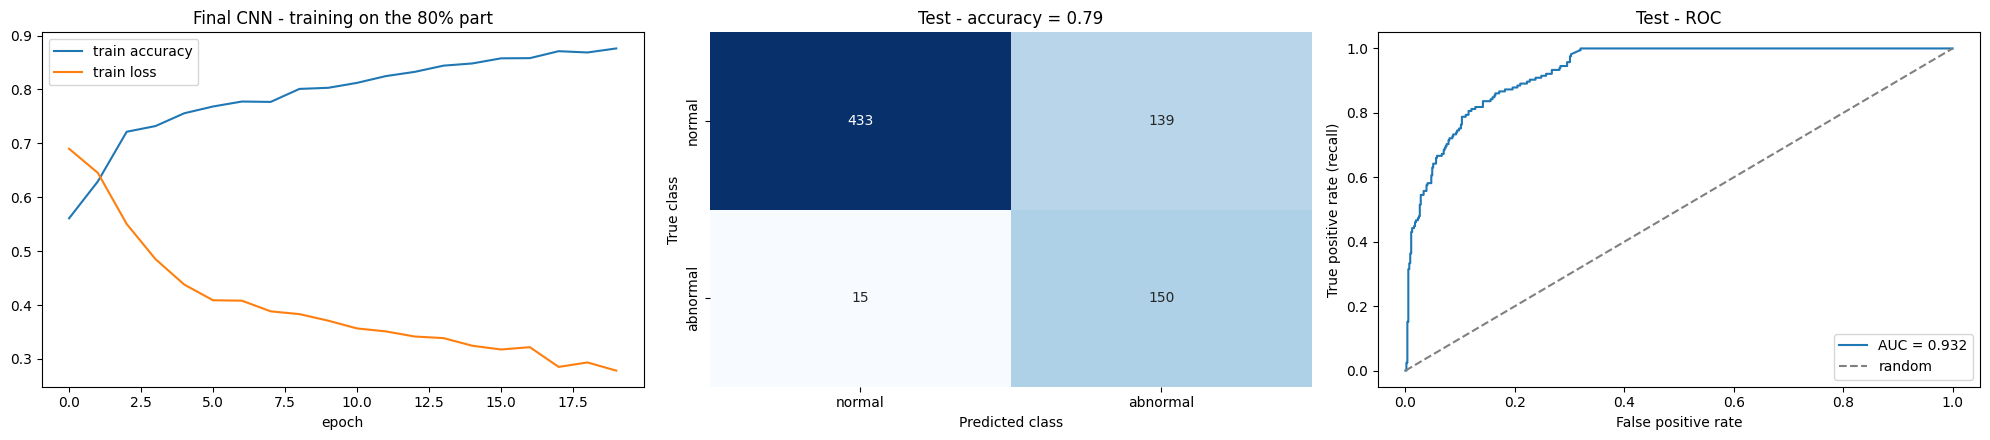

In [14]:
# ==================== TEST: the final CNN learns on the whole 80% part, then is tested ONCE on the 20% ====================
# the same settings as the folds (20 epochs): nothing is chosen with the test wavs
keras.utils.set_random_seed(0)
final_model = build_cnn()
final_history = final_model.fit(X_train, y_train, epochs=EPOCHS, batch_size=BATCH_SIZE, class_weight=class_weight,
                                verbose=0)
print("final CNN trained on", len(y_train), "wavs (the 80% train part)")

y_test_prob = final_model.predict(X_test, verbose=0).ravel()
y_test_pred = (y_test_prob > 0.5).astype(int)
false_positive_rate, true_positive_rate, thresholds = roc_curve(y_test, y_test_prob)
test_results = {
    "accuracy": accuracy_score(y_test, y_test_pred),
    "precision": precision_score(y_test, y_test_pred),
    "recall": recall_score(y_test, y_test_pred),
    "f1": f1_score(y_test, y_test_pred),
    "auc": auc(false_positive_rate, true_positive_rate),
}
report = classification_report(y_test, y_test_pred, target_names=["normal", "abnormal"])
print(report)
print({name: round(value, 3) for name, value in test_results.items()})
with open(plots_folder + "tp7_cnn_test_report.txt", "w") as f:
    f.write("CNN - test set (" + str(len(y_test)) + " wavs never seen)\n\n" + report)

# ONE test figure: the training curve of the final CNN, the confusion matrix and the ROC curve of the test wavs
plt.figure(figsize=(20, 4.5))
plt.subplot(1, 3, 1)
plt.plot(final_history.history["accuracy"], label="train accuracy")
plt.plot(final_history.history["loss"], label="train loss")
plt.title("Final CNN - training on the 80% part")
plt.xlabel("epoch")
plt.legend()
plt.subplot(1, 3, 2)
PlotConfusionMatrix(confusion_matrix(y_test, y_test_pred), "Test - accuracy = {:.2f}".format(test_results["accuracy"]))
plt.subplot(1, 3, 3)
plot_roc(y_test, y_test_prob, "Test - ROC")
plt.tight_layout()
plt.savefig(plots_folder + "tp7_cnn_test.png")
plt.show()

# the probabilities of this model, for the ensemble (notebook 08): out-of-fold (validation) + test
save_data({"model": "CNN", "train_names": list(files[~is_test]), "train_y": list(y_train), "fold": list(oof_fold),
           "oof_prob": list(oof_prob), "test_names": list(files[is_test]), "test_y": list(y_test),
           "test_prob": list(y_test_prob)}, project_folder + "probs_cnn.data")

In [15]:
# ==================== MLflow (Service 6) ====================
# the MLflow container must be running: docker compose up -d mlflow-server
# a new experiment for the final protocol (validation + test): the old runs stay in audio_benchmark (history)
mlflow.set_tracking_uri("http://localhost:5000")
mlflow.set_experiment("audio_benchmark_final")

with mlflow.start_run(run_name="cnn"):
    mlflow.log_param("model", "CNN")
    mlflow.log_param("features", "mel spectrogram 40 x 157 (5 s, 2000 Hz)")
    mlflow.log_param("layers", "3 x (Conv2D + MaxPooling) + Flatten + Dense 32 + Dropout 0.5 + Dense 1")
    mlflow.log_param("optimizer", "adam")
    mlflow.log_param("learning_rate", 0.001)
    mlflow.log_param("epochs", EPOCHS)
    mlflow.log_param("batch_size", BATCH_SIZE)
    mlflow.log_param("class_weight", "balanced")
    mlflow.log_param("n_folds", 3)
    mlflow.log_param("protocol", "3 folds on the 80% train part (validation), final model on the 80%, tested on the 20%")
    mlflow.log_param("n_train", len(y_train))
    mlflow.log_param("n_test", len(y_test))

    for metric in metrics:
        mlflow.log_metric("mean_" + metric, table[metric].mean())    # validation: the mean of the 3 folds
        mlflow.log_metric("test_" + metric, test_results[metric])    # test: the final CNN on the 20% test set
    for r in results:    # the results of each fold, also here: fold1_accuracy, ..., fold3_auc
        for metric in metrics:
            mlflow.log_metric("fold" + str(r["fold"]) + "_" + metric, r[metric])

    # the plots: plots/validation/ (the 3 folds) and plots/test/ (the final CNN)
    for fold in [1, 2, 3]:
        mlflow.log_artifact(plots_folder + "tp7_cnn_val_fold" + str(fold) + ".png", artifact_path="plots/validation")
    mlflow.log_artifact(plots_folder + "tp7_cnn_val_summary.png", artifact_path="plots/validation")
    mlflow.log_artifact(plots_folder + "tp7_cnn_test.png", artifact_path="plots/test")
    mlflow.log_artifact(plots_folder + "tp7_cnn_test_report.txt", artifact_path="plots/test")

    mlflow.keras.log_model(final_model, "model")    # the final CNN (the tested one: it is the one exported to ONNX)

    # the 3 folds: 1 small run per fold INSIDE the "cnn" run (nested=True), with its curves and its results
    for r in results:
        fold = r["fold"]
        h = histories[fold - 1].history    # what Keras saved after each epoch of this fold
        with mlflow.start_run(run_name="cnn_fold" + str(fold), nested=True):
            mlflow.log_param("fold", fold)
            # training vs validation: 1 point per epoch -> MLflow draws the curves (tab "Model metrics")
            for epoch in range(EPOCHS):
                mlflow.log_metric("train_loss", h["loss"][epoch], step=epoch + 1)
                mlflow.log_metric("val_loss", h["val_loss"][epoch], step=epoch + 1)
                mlflow.log_metric("train_accuracy", h["accuracy"][epoch], step=epoch + 1)
                mlflow.log_metric("val_accuracy", h["val_accuracy"][epoch], step=epoch + 1)
            # the results on the validation wavs of this fold (val_accuracy = the last point of its curve)
            mlflow.log_metric("val_precision", r["precision"])
            mlflow.log_metric("val_recall", r["recall"])
            mlflow.log_metric("val_f1", r["f1"])
            mlflow.log_metric("val_auc", r["auc"])
            mlflow.log_artifact(plots_folder + "tp7_cnn_val_fold" + str(fold) + ".png", artifact_path="plots/validation")

2026/11/27 11:10:55 WARNING mlflow.keras.save: You are saving a Keras model without specifying model signature.


2026/11/27 11:19:17 WARNING mlflow.utils.environment: Encountered an unexpected error while inferring pip requirements (model URI: C:\Users\farah\AppData\Local\Temp\tmpdy7io_p9\model, flavor: keras). Fall back to return ['keras==3.12.4']. Set logging level to DEBUG to see the full traceback. 


2026/11/27 11:19:18 WARNING mlflow.models.model: Model logged without a signature and input example. Please set `input_example` parameter when logging the model to auto infer the model signature.


🏃 View run cnn_fold1 at: http://localhost:5000/#/experiments/2/runs/5a0009d9ab414508ab28a309ebebde8e
🧪 View experiment at: http://localhost:5000/#/experiments/2


🏃 View run cnn_fold2 at: http://localhost:5000/#/experiments/2/runs/93650feea17041258eb00fa574da6bcc
🧪 View experiment at: http://localhost:5000/#/experiments/2


🏃 View run cnn_fold3 at: http://localhost:5000/#/experiments/2/runs/0622552b45a047cc867c9a5fba7be799
🧪 View experiment at: http://localhost:5000/#/experiments/2


🏃 View run cnn at: http://localhost:5000/#/experiments/2/runs/d4e6661bed084af79cfee5d2f1f791cd
🧪 View experiment at: http://localhost:5000/#/experiments/2
